In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

[codecarbon WARNING @ 15:35:09] Nvidia GPU detected but pynvml initialization failed. Please ensure NVIDIA drivers are properly installed.


In [2]:
TEXT_COL = "sentence"
LABEL_COL = "label"

SAMPLE_SIZE = 200
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased"
]

In [3]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

In [4]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):

    hist1, bin_edges = np.histogram(dist1, bins=bins, range=value_range)
    hist2, _ = np.histogram(dist2, bins=bin_edges)

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()

    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))

    return chi_dist

In [46]:
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )

    similarity_matrix = (
        normalized_embeddings
        @ normalized_embeddings.T
    )

    return similarity_matrix.numpy()

In [47]:
from collections import defaultdict
from itertools import combinations

import numpy as np
import torch
import torch.nn.functional as F


def build_label_to_indices(labels):
    label_to_indices = defaultdict(list)

    for sample_index, sample_labels in enumerate(labels):
        if isinstance(sample_labels, str):
            sample_labels = [sample_labels]

        # Remove duplicate labels inside one sample
        sample_labels = {
            str(label)
            for label in sample_labels
        }

        for label in sample_labels:
            label_to_indices[label].append(
                sample_index
            )

    return {
        label: np.asarray(indices, dtype=int)
        for label, indices
        in label_to_indices.items()
    }

In [48]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_to_indices = build_label_to_indices(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []
    scores_by_label = {}

    for label in sorted(label_to_indices):
        indices = label_to_indices[label]

        if len(indices) < 2:
            print(
                f"Label {label}: skipped, "
                f"only {len(indices)} sample"
            )
            continue

        label_scores = []

        # Every pair inside this label group
        for first_position in range(
            len(indices)
        ):
            for second_position in range(
                first_position + 1,
                len(indices),
            ):
                first_index = indices[
                    first_position
                ]

                second_index = indices[
                    second_position
                ]

                score = similarity_matrix[
                    first_index,
                    second_index,
                ]

                label_scores.append(
                    float(score)
                )

        label_scores = np.asarray(
            label_scores,
            dtype=float,
        )

        scores_by_label[label] = label_scores

        # A pair can appear once for each shared label.
        # This follows the independent-label definition.
        all_scores.extend(label_scores)

        print(
            f"Label {label}: "
            f"{len(indices)} samples, "
            f"{len(label_scores)} pairs"
        )

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label pairs were found."
        )

    print(
        "Total within-label pairs:",
        len(all_scores),
    )

    if return_by_label:
        return all_scores, scores_by_label

    return all_scores

In [49]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_to_indices = build_label_to_indices(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    unique_labels = sorted(
        label_to_indices.keys()
    )

    all_scores = []
    scores_by_label_pair = {}

    for first_label, second_label in combinations(
        unique_labels,
        2,
    ):
        first_indices = label_to_indices[
            first_label
        ]

        second_indices = label_to_indices[
            second_label
        ]

        label_pair_scores = []

        # Avoid counting the same underlying text pair
        # twice inside one label-pair comparison.
        seen_source_pairs = set()

        for first_index in first_indices:
            for second_index in second_indices:
                # Never compare one text with itself
                if first_index == second_index:
                    continue

                source_pair = tuple(
                    sorted(
                        (
                            int(first_index),
                            int(second_index),
                        )
                    )
                )

                if source_pair in seen_source_pairs:
                    continue

                seen_source_pairs.add(
                    source_pair
                )

                score = similarity_matrix[
                    first_index,
                    second_index,
                ]

                label_pair_scores.append(
                    float(score)
                )

        if not label_pair_scores:
            continue

        label_pair = (
            first_label,
            second_label,
        )

        label_pair_scores = np.asarray(
            label_pair_scores,
            dtype=float,
        )

        scores_by_label_pair[
            label_pair
        ] = label_pair_scores

        all_scores.extend(
            label_pair_scores
        )

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label pairs were found."
        )

    print(
        "Number of label-pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total between-label pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [12]:
train_df = pd.read_json("data/ecthr_cases_raw/train.jsonl", lines=True)
validation_df = pd.read_json("data/ecthr_cases_raw/dev.jsonl", lines=True)
test_df = pd.read_json("data/ecthr_cases_raw/test.jsonl", lines=True)

print(train_df.shape)
print(validation_df.shape)
print(test_df.shape)

(9000, 12)
(1000, 12)
(1000, 12)


In [13]:
train_df.head()

,case_id,case_no,title,judgment_date,facts,applicants,defendants,allegedly_violated_articles,violated_articles,court_assessment_references,silver_rationales,gold_rationales
0,001-59587,25702/94,CASE OF K. AND T. v. FINLAND,2001-07-12,[11. At the beginning of the events relevant ...,"[K., T.]",[FINLAND],"[13, 8]",[8],"{'8': ['12', '140', '155', '156', '157', '158'...","[1, 13, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30...",[]
1,001-59591,42527/98,CASE OF PRINCE HANS-ADAM II OF LIECHTENSTEIN v...,2001-07-12,[9. The applicant is the monarch of Liechtens...,[PRINCE HANS-ADAM II OF LIECHTENSTEIN],[GERMANY],"[14, P1-1, 6]",[],"{'6': ['12', '15', '24', '25', '26', '27', '28...","[3, 6]",[]
2,001-59590,33071/96,CASE OF MALHOUS v. THE CZECH REPUBLIC,2001-07-12,[9. In June 1949 plots of agricultural land o...,[MALHOUS],[CZECH REPUBLIC],[6],[6],"{'6': ['13', '14', '35', '40', '41', '42', '43...","[4, 5]",[]
3,001-59588,29032/95,CASE OF FELDEK v. SLOVAKIA,2001-07-12,"[8. In 1991 Mr Dušan Slobodník, a research wo...",[FELDEK],[SLOVAKIA],"[14, 10, 9]",[10],{'10': ['35']},[27],[]
4,001-59589,44759/98,CASE OF FERRAZZINI v. ITALY,2001-07-12,"[9. The applicant is an Italian citizen, born...",[FERRAZZINI],[ITALY],"[14, 6]",[],"{'6': ['13', '14', '35', '40', '41', '42', '43...",[4],[]


In [19]:
train_raw = pd.read_json("data/ecthr_cases_raw/train.jsonl", lines=True)
validation_raw = pd.read_json("data/ecthr_cases_raw/dev.jsonl", lines=True)
test_raw = pd.read_json("data/ecthr_cases_raw/test.jsonl", lines=True)

raw_df = pd.concat(
    [train_raw, validation_raw, test_raw],
    ignore_index=True,
)


def get_unique_labels(dataframe, column):
    return sorted(
        dataframe[column]
        .explode()
        .dropna()
        .astype(str)
        .unique()
    )


alleged_labels = get_unique_labels(
    raw_df,
    "allegedly_violated_articles",
)

violated_labels = get_unique_labels(
    raw_df,
    "violated_articles",
)

print(
    "Allegedly violated:",
    len(alleged_labels),
    alleged_labels,
)

print(
    "Actually violated:",
    len(violated_labels),
    violated_labels,
)

Allegedly violated: 33 ['10', '11', '12', '13', '14', '15', '17', '18', '2', '3', '34', '38', '39', '4', '46', '5', '6', '7', '8', '9', 'P1-1', 'P1-2', 'P1-3', 'P12-1', 'P3-1', 'P4-2', 'P4-4', 'P6-3', 'P7-1', 'P7-2', 'P7-3', 'P7-4', 'P7-5']
Actually violated: 29 ['10', '11', '12', '13', '14', '18', '2', '3', '34', '38', '4', '46', '5', '6', '7', '8', '9', 'P1-1', 'P1-2', 'P1-3', 'P12-1', 'P4-2', 'P4-4', 'P6-1', 'P6-3', 'P7-1', 'P7-2', 'P7-3', 'P7-4']


In [23]:
import pandas as pd


def prepare_dataframe(source_df, split_name):
    prepared_df = pd.DataFrame({
        "case_id": source_df["case_id"].astype(str),

        # 将一个案件的多个facts段落拼接成完整文本
        "text": source_df["facts"].apply(
            lambda paragraphs: "\n\n".join(paragraphs)
        ),

        # Riyadi论文使用的33类multi-label目标
        "labels": source_df[
            "allegedly_violated_articles"
        ].apply(list),

        "split": split_name,
    })

    return prepared_df


train_final = prepare_dataframe(
    train_raw,
    "train",
)

validation_final = prepare_dataframe(
    validation_raw,
    "validation",
)

test_final = prepare_dataframe(
    test_raw,
    "test",
)


df = pd.concat(
    [
        train_final,
        validation_final,
        test_final,
    ],
    ignore_index=True,
)


print("Final shape:", df.shape)
print("\nSplit counts:")
print(df["split"].value_counts())

df.head()

Final shape: (11000, 4)

Split counts:
split
train         9000
validation    1000
test          1000
Name: count, dtype: int64


,case_id,text,labels,split
0,001-59587,11. At the beginning of the events relevant t...,"[13, 8]",train
1,001-59591,9. The applicant is the monarch of Liechtenst...,"[14, P1-1, 6]",train
2,001-59590,9. In June 1949 plots of agricultural land ow...,[6],train
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research wor...","[14, 10, 9]",train
4,001-59589,"9. The applicant is an Italian citizen, born ...","[14, 6]",train


In [24]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"[?|!|\'|\"|#]", "", text)
    text = re.sub(r"[.|,|)|(|\\|/]", " ", text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def load_and_clean_dataset(csv_file):
    df = pd.read_csv(csv_file)
    df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates().copy()

    df["clean_sentence"] = df[TEXT_COL].apply(clean_text)
    df["length"] = df["clean_sentence"].apply(len)

    print(df.head())
    print(df[LABEL_COL].value_counts())
    print(df.shape)

    return df

In [25]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [ ]:
import re
TEXT_COL = "text"
LABEL_COL = "labels"


def clean_text(text):
    """
    For BERT models, preserve punctuation and legal symbols.
    Only normalize whitespace.
    """
    text = str(text)

    # Replace line breaks and non-breaking spaces
    text = text.replace("\n", " ")
    text = text.replace("\r", " ")
    text = text.replace("\u00a0", " ")

    # Merge repeated whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def prepare_and_clean_dataframe(df):
    """
    Clean the existing ECtHR DataFrame.
    No CSV loading is required.
    """
    required_columns = {
        "case_id",
        TEXT_COL,
        LABEL_COL,
        "split",
    }

    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Missing columns: {missing_columns}"
        )

    result = df[
        [
            "case_id",
            TEXT_COL,
            LABEL_COL,
            "split",
        ]
    ].copy()

    # Remove rows without text
    result = result.dropna(
        subset=[TEXT_COL]
    )

    # Each case should occur only once
    result = result.drop_duplicates(
        subset=["case_id"],
        keep="first",
    )

    # Ensure labels are Python lists
    result[LABEL_COL] = result[LABEL_COL].apply(
        lambda labels: list(labels)
    )

    # Clean text
    result["clean_sentence"] = result[
        TEXT_COL
    ].apply(clean_text)

    # Remove empty text after cleaning
    result = result[
        result["clean_sentence"].str.len() > 0
    ].copy()

    # Character length
    result["char_length"] = result[
        "clean_sentence"
    ].str.len()

    # Word-level length
    result["length"] = result[
        "clean_sentence"
    ].str.split().str.len()

    result = result.reset_index(drop=True)

    print("Preview:")
    print(
        result[
            [
                "case_id",
                "labels",
                "split",
                "length",
            ]
        ].head()
    )

    print("\nSplit counts:")
    print(result["split"].value_counts())

    print("\nLabel counts:")
    print(
        result[LABEL_COL]
        .explode()
        .value_counts()
    )

    print("\nEmpty-label cases:")
    print(
        result[LABEL_COL]
        .apply(len)
        .eq(0)
        .sum()
    )

    print("\nShape:")
    print(result.shape)

    return result

In [27]:
df.head()

,case_id,text,labels,split
0,001-59587,11. At the beginning of the events relevant t...,"[13, 8]",train
1,001-59591,9. The applicant is the monarch of Liechtenst...,"[14, P1-1, 6]",train
2,001-59590,9. In June 1949 plots of agricultural land ow...,[6],train
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research wor...","[14, 10, 9]",train
4,001-59589,"9. The applicant is an Italian citizen, born ...","[14, 6]",train


In [28]:
df = prepare_and_clean_dataframe(df)

Preview:
     case_id         labels  split  length
0  001-59587        [13, 8]  train    6884
1  001-59591  [14, P1-1, 6]  train    2758
2  001-59590            [6]  train    1347
3  001-59588    [14, 10, 9]  train    3859
4  001-59589        [14, 6]  train     571

Split counts:
split
train         9000
validation    1000
test          1000
Name: count, dtype: int64

Label counts:
labels
6        6225
3        2210
5        2038
13       1900
P1-1     1881
8        1397
2         774
34        660
10        611
14        510
11        244
46        227
39        160
38        123
9         101
7          92
P1-3       74
P4-2       63
18         61
P7-4       41
4          34
17         33
12         22
P7-2       22
P1-2       21
P7-1       12
P4-4       10
15          9
P12-1       6
P7-5        4
P7-3        3
P3-1        1
P6-3        1
Name: count, dtype: int64

Empty-label cases:
46

Shape:
(11000, 7)


In [29]:
df.head()

,case_id,text,labels,split,clean_sentence,char_length,length
0,001-59587,11. At the beginning of the events relevant t...,"[13, 8]",train,11. At the beginning of the events relevant to...,40009,6884
1,001-59591,9. The applicant is the monarch of Liechtenst...,"[14, P1-1, 6]",train,9. The applicant is the monarch of Liechtenste...,17555,2758
2,001-59590,9. In June 1949 plots of agricultural land ow...,[6],train,9. In June 1949 plots of agricultural land own...,8289,1347
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research wor...","[14, 10, 9]",train,"8. In 1991 Mr Dušan Slobodník, a research work...",22980,3859
4,001-59589,"9. The applicant is an Italian citizen, born ...","[14, 6]",train,"9. The applicant is an Italian citizen, born i...",3406,571


In [30]:
def add_length_quantile_groups(
    df,
    num_quantiles=100,
):
    result = df.copy()

    quantile_ids = pd.qcut(
        result["length"],
        q=num_quantiles,
        labels=False,
        duplicates="drop",
    )

    result["quantiles"] = (
        "Q"
        + (quantile_ids + 1)
        .astype("Int64")
        .astype(str)
    )

    print(
        result["quantiles"]
        .value_counts()
        .sort_index(
            key=lambda index: (
                index.str
                .replace("Q", "", regex=False)
                .astype(int)
            )
        )
    )

    return result

In [31]:
df = add_length_quantile_groups(
    df,
    num_quantiles=100,
)

quantiles
Q1      115
Q2      107
Q3      109
Q4      115
Q5      106
       ... 
Q96     110
Q97     110
Q98     110
Q99     110
Q100    110
Name: count, Length: 100, dtype: int64


In [32]:
df.head()

,case_id,text,labels,split,clean_sentence,char_length,length,quantiles
0,001-59587,11. At the beginning of the events relevant t...,"[13, 8]",train,11. At the beginning of the events relevant to...,40009,6884,Q98
1,001-59591,9. The applicant is the monarch of Liechtenst...,"[14, P1-1, 6]",train,9. The applicant is the monarch of Liechtenste...,17555,2758,Q84
2,001-59590,9. In June 1949 plots of agricultural land ow...,[6],train,9. In June 1949 plots of agricultural land own...,8289,1347,Q60
3,001-59588,"8. In 1991 Mr Dušan Slobodník, a research wor...","[14, 10, 9]",train,"8. In 1991 Mr Dušan Slobodník, a research work...",22980,3859,Q91
4,001-59589,"9. The applicant is an Italian citizen, born ...","[14, 6]",train,"9. The applicant is an Italian citizen, born i...",3406,571,Q29


In [33]:
TEXT_COL = "clean_sentence	"
LABEL_COL = "labels"

In [34]:
print(df.columns)
print(df.shape)

Index(['case_id', 'text', 'labels', 'split', 'clean_sentence', 'char_length',
       'length', 'quantiles'],
      dtype='str')
(11000, 8)


In [41]:
def sample_from_length_groups(
    df,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
):
    sampling_pool = df.copy().reset_index(drop=True)

    if sample_size > len(sampling_pool):
        raise ValueError(
            f"sample_size={sample_size} exceeds "
            f"dataset size={len(sampling_pool)}"
        )

    # Calculate word count if it does not exist
    if "length" not in sampling_pool.columns:
        sampling_pool["length"] = (
            sampling_pool["clean_sentence"]
            .str.split()
            .str.len()
        )

    # Create length quantile groups using the whole dataset
    effective_quantiles = min(
        num_quantiles,
        sample_size,
        sampling_pool["length"].nunique(),
    )

    sampling_pool["_length_group"] = pd.qcut(
        sampling_pool["length"],
        q=effective_quantiles,
        labels=False,
        duplicates="drop",
    )

    number_of_groups = (
        sampling_pool["_length_group"].nunique()
    )

    samples_per_group = (
        sample_size // number_of_groups
    )

    rng = np.random.default_rng(random_seed)
    sampled_parts = []

    for _, group in sampling_pool.groupby(
        "_length_group",
        observed=True,
    ):
        number_to_sample = min(
            samples_per_group,
            len(group),
        )

        sampled_parts.append(
            group.sample(
                n=number_to_sample,
                random_state=int(
                    rng.integers(0, 2**32 - 1)
                ),
            )
        )

    sampled_df = pd.concat(sampled_parts)

    # If quantile duplication caused fewer than 200 samples,
    # randomly fill the remaining positions.
    remaining_count = (
        sample_size - len(sampled_df)
    )

    if remaining_count > 0:
        remaining_pool = sampling_pool.drop(
            index=sampled_df.index
        )

        additional_samples = remaining_pool.sample(
            n=remaining_count,
            random_state=random_seed,
        )

        sampled_df = pd.concat(
            [sampled_df, additional_samples]
        )

    # Shuffle and clean temporary columns
    sampled_df = (
        sampled_df
        .sample(
            frac=1,
            random_state=random_seed,
        )
        .drop(columns=["_length_group"])
        .reset_index(drop=True)
    )

    print("Original Dataset Size:", len(df))
    print("Actual Sample Size:", len(sampled_df))
    print(
        "Minimum Word Count:",
        sampled_df["length"].min(),
    )
    print(
        "Average Word Count:",
        sampled_df["length"].mean(),
    )
    print(
        "Maximum Word Count:",
        sampled_df["length"].max(),
    )

    return sampled_df

In [ ]:
def compute_embeddings(texts, model_name, batch_size=64, max_token=128):
    tokenizer = BertTokenizer.from_pretrained(model_name)
    model = BertModel.from_pretrained(model_name)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            batch_embeddings = outputs.last_hidden_state.mean(dim=1).cpu()

        embeddings.append(batch_embeddings)

    return torch.cat(embeddings)

In [37]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [38]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(f"\nRunning model: {model_name}")

    texts = sampled_df["clean_sentence"].tolist()
    labels = sampled_df[label_col].values

    # 1. Compute embeddings only once
    embeddings = compute_embeddings(
        texts,
        model_name,
        batch_size=batch_size,
        max_token=max_token
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = calculate_within_label_cosine_distribution(
        embeddings=embeddings,
        labels=labels,
        return_by_label=True
    )

    same_eta = asymmetry_eta(same_scores)

    # 3. Different-label cosine distribution
    # This step computes all different-label cosine similarities only once.
    diff_scores_original, diff_label = calculate_between_label_cosine_distribution(
        embeddings=embeddings,
        labels=labels,
        return_by_label_pair=True
    )


    # 5. Bootstrap different-label distribution
    # Important: this function only samples from existing diff_label[pair].
    # It does NOT recompute cosine similarity.
    bootstrap_chi2_df, chi2_summary = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth
    )

    summary = {
        "model": model_name,

        # same-label
        "same_mean": np.mean(same_scores),
        "same_eta": same_eta,
        "same_abs_eta": abs(same_eta),
        "same_n_pairs": len(same_scores),

        # bootstrapped different-label
        "diff_mean": chi2_summary["diff_mean"],
        "diff_n_pairs": chi2_summary["diff_n_pairs"],
        "mean_gap": chi2_summary["mean_gap"],
        "abs_mean_gap": chi2_summary["abs_mean_gap"],

        # chi-square distance
        "chi2_distance": chi2_summary["chi2_distance"],
        "chi2_distance_std": chi2_summary["chi2_distance_std"],

        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    print("\nSummary:")
    print("Same mean:", summary["same_mean"])
    print("Diff mean:", summary["diff_mean"])
    print("Mean gap:", summary["mean_gap"])
    print("Chi2 distance:", summary["chi2_distance"])
    print("Chi2 distance std:", summary["chi2_distance_std"])
    print("Same eta:", summary["same_eta"])

    return {
        "summary": summary,

        # already-computed distributions
        "same_scores": same_scores,
        "diff_scores_original": diff_scores_original,

        # same-label and diff-label grouped scores
        "scores_by_label": scores_by_label,
        "diff_label": diff_label,

        # bootstrap result
        "bootstrap_chi2_df": bootstrap_chi2_df,

        # embeddings and labels
        "embeddings": embeddings,
        "labels": labels
    }

In [ ]:
def running_sizes_chi2_bootstrap(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=MODELS,
    batch_size=64,
    max_token=128,
    label_col="labels",
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):
    summary_results = []
    full_results = {}

    for repetition in range(num_repetitions):
        print("=================================================")
        print(f"Repetition {repetition + 1}/{num_repetitions}")

        random_seed = np.random.randint(1000)

        sampled_df = sample_from_length_groups(
            grouped_df,
            sample_size=sample_size,
            num_quantiles=num_quantiles,
            random_seed=random_seed
        )

        print("Actual Sample Size:", len(sampled_df))
        print("Label counts:")
        print(sampled_df[label_col].value_counts())

        for model_name in models:
            result = run_one_model_chi2_bootstrap(
                sampled_df=sampled_df,
                model_name=model_name,
                batch_size=batch_size,
                max_token=max_token,
                label_col=label_col,
                n_bootstrap=n_bootstrap,
                random_seed=random_seed,
                bins=bins,
                value_range=value_range,
                eta_bandwidth=eta_bandwidth
            )

            summary = result["summary"].copy()

            summary["repetition"] = repetition + 1
            summary["random_seed"] = random_seed
            summary["sample_size"] = sample_size

            summary_results.append(summary)

            full_results[(repetition + 1, model_name)] = result
---------------------------------------------------------------------------
ValueError                                Traceback (most recent call last)
Cell In[45], line 1
----> 1 results = running_sizes_chi2_bootstrap(
      2     grouped_df=df,
      3     sample_size=200,
      4     num_quantiles=100,

Cell In[39], line 36, in running_sizes_chi2_bootstrap(grouped_df, sample_size, num_quantiles, num_repetitions, models, batch_size, max_token, label_col, n_bootstrap, bins, value_range, eta_bandwidth)
     32         print("Label counts:")
     33         print(sampled_df[label_col].value_counts())
     34 
     35         for model_name in models:
---> 36             result = run_one_model_chi2_bootstrap(
     37                 sampled_df=sampled_df,
     38                 model_name=model_name,
     39                 batch_size=batch_size,

Cell In[38], line 27, in run_one_model_chi2_bootstrap(sampled_df, model_name, batch_size, max_token, label_col, n_bootstrap, random_seed, bins, value_range, eta_bandwidth)
     23         max_token=max_token
     24     )
     25 
     26     # 2. Same-label cosine distribution
---> 27     same_scores, scores_by_label = calculate_within_label_cosine_distribution(
     28         embeddings=embeddings,
     29         labels=labels,
     30         return_by_label=True

Cell In[6], line 14, in calculate_within_label_cosine_distribution(embeddings, labels, return_by_label)
     10     all_scores = []#saving all results from different labels
     11     scores_by_label = {}#dictionary, saving results for each label
     12 
     13     for lab in unique_labels:
---> 14         idx = np.where(labels == lab)[0]
     15 
     16         # Need at least 2 samples to calculate pairwise cosine
     17         if len(idx) < 2:

ValueError: operands could not be broadcast together with shapes (200,) (0,)
    summary_df = pd.DataFrame(summary_results)

    return {
        "summary_df": summary_df,
        "full_results": full_results
    }

In [40]:
model_order = [
    "recobo/agriculture-bert-uncased",
    "google-bert/bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "allenai/scibert_scivocab_uncased",
    "Lianglab/PharmBERT-uncased",
    "recobo/chemical-bert-uncased",
    "nlpaueb/legal-bert-base-uncased"
]

In [42]:
sampled_df = sample_from_length_groups(
    df,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
)

Original Dataset Size: 11000
Actual Sample Size: 200
Minimum Word Count: 118
Average Word Count: 1639.64
Maximum Word Count: 11284


In [50]:
results = running_sizes_chi2_bootstrap(
    grouped_df=df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=model_order,
    batch_size=64,
    max_token=128,
    label_col="labels",
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
)

summary_df = results["summary_df"]
summary_df

Repetition 1/3
Original Dataset Size: 11000
Actual Sample Size: 200
Minimum Word Count: 123
Average Word Count: 1676.06
Maximum Word Count: 17431
Actual Sample Size: 200
Label counts:
labels
[6]                  48
[5]                  12
[3]                  12
[13, 6]              11
[P1-1, 6]            11
                     ..
[13, P1-1, 46, 6]     1
[5, 7, 6]             1
[P1-3]                1
[5, 3, 8, 46, 18]     1
[2, 34]               1
Name: count, Length: 65, dtype: int64

Running model: recobo/agriculture-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/agriculture-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your d

Label 10: 7 samples, 21 pairs
Label 11: 6 samples, 15 pairs
Label 13: 38 samples, 703 pairs
Label 14: 8 samples, 28 pairs
Label 15: skipped, only 1 sample
Label 18: 3 samples, 3 pairs
Label 2: 16 samples, 120 pairs
Label 3: 52 samples, 1326 pairs
Label 34: 10 samples, 45 pairs
Label 38: 5 samples, 10 pairs
Label 39: 3 samples, 3 pairs
Label 4: 2 samples, 1 pairs
Label 46: 4 samples, 6 pairs
Label 5: 43 samples, 903 pairs
Label 6: 109 samples, 5886 pairs
Label 7: 3 samples, 3 pairs
Label 8: 32 samples, 496 pairs
Label 9: 2 samples, 1 pairs
Label P1-1: 26 samples, 325 pairs
Label P1-2: skipped, only 1 sample
Label P1-3: skipped, only 1 sample
Label P4-2: skipped, only 1 sample
Label P7-3: skipped, only 1 sample
Label P7-4: skipped, only 1 sample
Total within-label pairs: 9895
Number of label-pair types: 276
Total between-label pairs: 58732
Same-label target size: 9895
Different-label pair types: 276
Base sample per diff-label pair: 35

Summary:
Same mean: 0.9119403855917488
Diff mean: 0.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (55 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: nlpaueb/legal-bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Label 10: 16 samples, 120 pairs
Label 11: 5 samples, 10 pairs
Label 12: skipped, only 1 sample
Label 13: 37 samples, 666 pairs
Label 14: 8 samples, 28 pairs
Label 17: skipped, only 1 sample
Label 18: 2 samples, 1 pairs
Label 2: 11 samples, 55 pairs
Label 3: 38 samples, 703 pairs
Label 34: 13 samples, 78 pairs
Label 38: 3 samples, 3 pairs
Label 39: 4 samples, 6 pairs
Label 46: 5 samples, 10 pairs
Label 5: 35 samples, 595 pairs
Label 6: 124 samples, 7626 pairs
Label 7: skipped, only 1 sample
Label 8: 23 samples, 253 pairs
Label 9: 3 samples, 3 pairs
Label P1-1: 32 samples, 496 pairs
Label P1-2: skipped, only 1 sample
Label P1-3: skipped, only 1 sample
Label P7-1: skipped, only 1 sample
Label P7-4: skipped, only 1 sample
Total within-label pairs: 10653
Number of label-pair types: 253
Total between-label pairs: 54802
Same-label target size: 10653
Different-label pair types: 253
Base sample per diff-label pair: 42

Summary:
Same mean: 0.8911365863751618
Diff mean: 0.8766838077664331
Mean ga

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_n_pairs,mean_gap,abs_mean_gap,chi2_distance,chi2_distance_std,n_bootstrap,bins,value_range,repetition,random_seed,sample_size
0,recobo/agriculture-bert-uncased,0.911940,-0.417512,0.417512,9895,0.904813,9895.0,0.007127,0.007127,0.035363,0.001557,1000,50,"(-1, 1)",1,432,200
1,google-bert/bert-base-uncased,0.842966,-0.377362,0.377362,9895,0.834218,9895.0,0.008747,0.008747,0.031109,0.001311,1000,50,"(-1, 1)",1,432,200
2,ahmedrachid/FinancialBERT,0.896405,-0.428187,0.428187,9895,0.892024,9895.0,0.004381,0.004381,0.009622,0.000786,1000,50,"(-1, 1)",1,432,200
3,allenai/scibert_scivocab_uncased,0.889004,-0.459949,0.459949,9895,0.883173,9895.0,0.005832,0.005832,0.024112,0.001236,1000,50,"(-1, 1)",1,432,200
4,Lianglab/PharmBERT-uncased,0.861098,-0.469663,0.469663,9895,0.857014,9895.0,0.004083,0.004083,0.008819,0.000729,1000,50,"(-1, 1)",1,432,200
5,recobo/chemical-bert-uncased,0.940680,-0.650568,0.650568,9895,0.945247,9895.0,-0.004567,0.004567,0.008715,0.000809,1000,50,"(-1, 1)",1,432,200
6,nlpaueb/legal-bert-base-uncased,0.885891,-0.336875,0.336875,9895,0.877087,9895.0,0.008804,0.008804,0.025803,0.001326,1000,50,"(-1, 1)",1,432,200
7,recobo/agriculture-bert-uncased,0.915177,-0.490754,0.490754,10766,0.902936,10766.0,0.012241,0.012241,0.063339,0.001991,1000,50,"(-1, 1)",2,97,200
8,google-bert/bert-base-uncased,0.857405,-0.386659,0.386659,10766,0.834164,10766.0,0.023242,0.023242,0.101770,0.002297,1000,50,"(-1, 1)",2,97,200
9,ahmedrachid/FinancialBERT,0.898707,-0.413396,0.413396,10766,0.895300,10766.0,0.003407,0.003407,0.013554,0.000953,1000,50,"(-1, 1)",2,97,200


In [51]:
metric_summary_df = (
    summary_df
    .groupby("model", as_index=False)
    .agg(
        # Cosine similarity
        same_mean_mean=("same_mean", "mean"),
        same_mean_std=("same_mean", "std"),

        diff_mean_mean=("diff_mean", "mean"),
        diff_mean_std=("diff_mean", "std"),

        # Same–different separation
        mean_gap_mean=("mean_gap", "mean"),
        mean_gap_std=("mean_gap", "std"),

        abs_mean_gap_mean=("abs_mean_gap", "mean"),
        abs_mean_gap_std=("abs_mean_gap", "std"),

        # Eta
        same_eta_mean=("same_eta", "mean"),
        same_eta_std=("same_eta", "std"),

        same_abs_eta_mean=("same_abs_eta", "mean"),
        same_abs_eta_std=("same_abs_eta", "std"),

        # Chi-square
        chi2_distance_mean=("chi2_distance", "mean"),

        # Variation caused by three different samples
        chi2_sampling_std=("chi2_distance", "std"),

        # Average bootstrap uncertainty within each run
        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        same_n_pairs_mean=("same_n_pairs", "mean"),
        diff_n_pairs_mean=("diff_n_pairs", "mean"),
    )
)

In [52]:
metric_summary_df["chi2_rank"] = (
    metric_summary_df["chi2_distance_mean"]
    .rank(
        ascending=False,
        method="min",
    )
)

metric_summary_df["mean_gap_rank"] = (
    metric_summary_df["mean_gap_mean"]
    .rank(
        ascending=False,
        method="min",
    )
)

# Smaller sampling variation is more stable
metric_summary_df["stability_rank"] = (
    metric_summary_df["chi2_sampling_std"]
    .rank(
        ascending=True,
        method="min",
    )
)

In [53]:
metric_summary_df["combined_rank_score"] = (
    metric_summary_df[
        [
            "chi2_rank",
            "mean_gap_rank",
        ]
    ]
    .mean(axis=1)
)

In [54]:
model_ranking_df = (
    metric_summary_df
    .sort_values(
        by=[
            "combined_rank_score",
            "chi2_distance_mean",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

model_ranking_df.insert(
    0,
    "final_rank",
    range(1, len(model_ranking_df) + 1),
)

In [55]:
display(
    model_ranking_df[
        [
            "final_rank",
            "model",

            "chi2_distance_mean",
            "chi2_sampling_std",
            "chi2_bootstrap_std_mean",
            "chi2_rank",

            "mean_gap_mean",
            "mean_gap_std",
            "mean_gap_rank",

            "same_eta_mean",
            "same_eta_std",

            "combined_rank_score",
        ]
    ]
)

,final_rank,model,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,chi2_rank,mean_gap_mean,mean_gap_std,mean_gap_rank,same_eta_mean,same_eta_std,combined_rank_score
0,1,google-bert/bert-base-uncased,0.067305,0.035362,0.001818,1.0,0.013694,0.008271,2.0,-0.371449,0.018875,1.5
1,2,Lianglab/PharmBERT-uncased,0.060254,0.047014,0.001643,2.0,0.011663,0.007147,4.0,-0.423494,0.040001,3.0
2,3,allenai/scibert_scivocab_uncased,0.054755,0.027796,0.001721,3.0,0.012493,0.005841,3.0,-0.448756,0.046081,3.0
3,4,nlpaueb/legal-bert-base-uncased,0.042445,0.015038,0.001558,5.0,0.014080,0.005099,1.0,-0.349897,0.081316,3.0
4,5,recobo/agriculture-bert-uncased,0.046856,0.014640,0.001706,4.0,0.010008,0.002618,5.0,-0.434699,0.049742,4.5
5,6,recobo/chemical-bert-uncased,0.037475,0.029682,0.001427,6.0,-0.000213,0.003846,7.0,-0.635538,0.017456,6.5
6,7,ahmedrachid/FinancialBERT,0.020110,0.014891,0.001066,7.0,0.006429,0.004417,6.0,-0.369462,0.089212,6.5


In [56]:
import numpy as np
import pandas as pd
import torch
import time
import gc

from datasets import Dataset
from sklearn.metrics import f1_score, accuracy_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)

In [ ]:
df["split"] = df["split"].replace({"dev": "validation"})

In [58]:
label_names = sorted(
    df["labels"]
    .explode()
    .dropna()
    .astype(str)
    .unique()
)

num_labels = len(label_names)

label2id = {
    label: index
    for index, label in enumerate(label_names)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

print("Number of labels:", num_labels)
print(label_names)

Number of labels: 33
['10', '11', '12', '13', '14', '15', '17', '18', '2', '3', '34', '38', '39', '4', '46', '5', '6', '7', '8', '9', 'P1-1', 'P1-2', 'P1-3', 'P12-1', 'P3-1', 'P4-2', 'P4-4', 'P6-3', 'P7-1', 'P7-2', 'P7-3', 'P7-4', 'P7-5']


In [59]:
train_df = (
    df[df["split"] == "train"]
    [["clean_sentence", "labels"]]
    .reset_index(drop=True)
)

validation_df = (
    df[df["split"] == "validation"]
    [["clean_sentence", "labels"]]
    .reset_index(drop=True)
)

test_df = (
    df[df["split"] == "test"]
    [["clean_sentence", "labels"]]
    .reset_index(drop=True)
)

print(train_df.shape)
print(validation_df.shape)
print(test_df.shape)

(9000, 2)
(1000, 2)
(1000, 2)


In [60]:
def encode_labels(labels):
    target = np.zeros(num_labels, dtype=np.float32)

    for label in labels:
        label = str(label)

        if label in label2id:
            target[label2id[label]] = 1.0

    return target.tolist()

In [61]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))


def compute_multilabel_metrics(eval_prediction):
    logits, true_labels = eval_prediction

    if isinstance(logits, tuple):
        logits = logits[0]

    probabilities = sigmoid(logits)

    predicted_labels = (
        probabilities >= 0.5
    ).astype(np.int32)

    true_labels = true_labels.astype(np.int32)

    return {
        "macro_f1": f1_score(
            true_labels,
            predicted_labels,
            average="macro",
            zero_division=0,
        ),
        "micro_f1": f1_score(
            true_labels,
            predicted_labels,
            average="micro",
            zero_division=0,
        ),
        "subset_accuracy": accuracy_score(
            true_labels,
            predicted_labels,
        ),
    }

In [62]:
def prepare_model_datasets(model_name, max_length=512):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    train_dataset = Dataset.from_pandas(
        train_df,
        preserve_index=False,
    )

    validation_dataset = Dataset.from_pandas(
        validation_df,
        preserve_index=False,
    )

    test_dataset = Dataset.from_pandas(
        test_df,
        preserve_index=False,
    )

    def preprocess(batch):
        encoded = tokenizer(
            batch["clean_sentence"],
            truncation=True,
            max_length=max_length,
        )

        encoded["labels"] = [
            encode_labels(labels)
            for labels in batch["labels"]
        ]

        return encoded

    train_dataset = train_dataset.map(
        preprocess,
        batched=True,
        remove_columns=["clean_sentence"],
    )

    validation_dataset = validation_dataset.map(
        preprocess,
        batched=True,
        remove_columns=["clean_sentence"],
    )

    test_dataset = test_dataset.map(
        preprocess,
        batched=True,
        remove_columns=["clean_sentence"],
    )

    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer
    )

    return (
        tokenizer,
        data_collator,
        train_dataset,
        validation_dataset,
        test_dataset,
    )

In [63]:
def fine_tune_one_model(
    model_name,
    seed,
    num_train_epochs=3,
    max_length=512,
    learning_rate=2e-5,
):
    print("=" * 60)
    print("Model:", model_name)
    print("Seed:", seed)

    set_seed(seed)

    (
        tokenizer,
        data_collator,
        train_dataset,
        validation_dataset,
        test_dataset,
    ) = prepare_model_datasets(
        model_name=model_name,
        max_length=max_length,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=num_labels,
        problem_type="multi_label_classification",
        label2id=label2id,
        id2label=id2label,
    )

    safe_model_name = model_name.replace("/", "__")

    output_dir = (
        f"fine_tuned_models/"
        f"{safe_model_name}/seed_{seed}"
    )

    training_args = TrainingArguments(
        output_dir=output_dir,

        num_train_epochs=num_train_epochs,
        learning_rate=learning_rate,
        weight_decay=0.01,
        warmup_ratio=0.1,

        # 512 tokens may consume substantial GPU memory
        per_device_train_batch_size=4,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=8,

        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=100,

        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,

        save_total_limit=1,
        fp16=torch.cuda.is_available(),

        report_to="none",
        seed=seed,
        data_seed=seed,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=validation_dataset,
        data_collator=data_collator,
        processing_class=tokenizer,
        compute_metrics=compute_multilabel_metrics,
    )

    start_time = time.perf_counter()

    trainer.train()

    training_seconds = time.perf_counter() - start_time

    test_metrics = trainer.evaluate(
        eval_dataset=test_dataset,
        metric_key_prefix="test",
    )

    result = {
        "model": model_name,
        "seed": seed,
        "training_seconds": training_seconds,
        "test_macro_f1": test_metrics["test_macro_f1"],
        "test_micro_f1": test_metrics["test_micro_f1"],
        "test_subset_accuracy": test_metrics[
            "test_subset_accuracy"
        ],
        "test_loss": test_metrics["test_loss"],
        "max_length": max_length,
        "epochs": num_train_epochs,
        "learning_rate": learning_rate,
    }

    del trainer
    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

In [64]:
model_order = [
    "recobo/agriculture-bert-uncased",
    "google-bert/bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "allenai/scibert_scivocab_uncased",
    "Lianglab/PharmBERT-uncased",
    "recobo/chemical-bert-uncased",
    "nlpaueb/legal-bert-base-uncased",
]

training_seeds = [42, 97, 903]

real_ranking_results = []

for model_name in model_order:
    for seed in training_seeds:
        try:
            result = fine_tune_one_model(
                model_name=model_name,
                seed=seed,
                num_train_epochs=3,
                max_length=512,
                learning_rate=2e-5,
            )

            real_ranking_results.append(result)

            # 每完成一次就保存，避免中断后结果丢失
            pd.DataFrame(
                real_ranking_results
            ).to_csv(
                "real_ranking_raw_results.csv",
                index=False,
            )

            print(result)

        except Exception as error:
            print(
                f"Training failed: "
                f"{model_name}, seed={seed}"
            )
            print(error)

Model: recobo/agriculture-bert-uncased
Seed: 42


Map:   0%|          | 0/9000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: recobo/agriculture-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if 

... (267 outputs left out)

/home/amyliu/Desktop/GR/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Training failed: nlpaueb/legal-bert-base-uncased, seed=903
on_train_begin must be called before on_evaluate


In [65]:
from pathlib import Path
import pandas as pd
import torch
import gc

from transformers import (
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
)

model_order = [
    "recobo/agriculture-bert-uncased",
    "google-bert/bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "allenai/scibert_scivocab_uncased",
    "Lianglab/PharmBERT-uncased",
    "recobo/chemical-bert-uncased",
    "nlpaueb/legal-bert-base-uncased",
]

training_seeds = [42, 97, 903]

recovered_results = []

for model_name in model_order:
    for seed in training_seeds:
        safe_model_name = model_name.replace("/", "__")

        run_directory = Path(
            f"fine_tuned_models/"
            f"{safe_model_name}/seed_{seed}"
        )

        checkpoints = sorted(
            run_directory.glob("checkpoint-*"),
            key=lambda path: int(
                path.name.split("-")[-1]
            ),
        )

        if not checkpoints:
            print("No checkpoint:", run_directory)
            continue

        # save_total_limit=1，所以通常只有最佳checkpoint
        checkpoint_directory = checkpoints[-1]

        print("=" * 60)
        print("Model:", model_name)
        print("Seed:", seed)
        print("Checkpoint:", checkpoint_directory)

        (
            tokenizer,
            data_collator,
            _,
            _,
            test_dataset,
        ) = prepare_model_datasets(
            model_name=model_name,
            max_length=512,
        )

        # 通过from_pretrained重新加载，避免Trainer内部加载问题
        model = (
            AutoModelForSequenceClassification
            .from_pretrained(checkpoint_directory)
        )

        evaluation_args = TrainingArguments(
            output_dir=(
                f"evaluation_tmp/"
                f"{safe_model_name}/seed_{seed}"
            ),
            per_device_eval_batch_size=8,
            report_to="none",

            # 避免NotebookProgressCallback错误
            disable_tqdm=True,

            # CPU不需要pin memory
            dataloader_pin_memory=False,
        )

        evaluation_trainer = Trainer(
            model=model,
            args=evaluation_args,
            data_collator=data_collator,
            processing_class=tokenizer,
            compute_metrics=compute_multilabel_metrics,
        )

        # predict也会读取labels并计算compute_metrics
        prediction_output = evaluation_trainer.predict(
            test_dataset,
            metric_key_prefix="test",
        )

        metrics = prediction_output.metrics

        result = {
            "model": model_name,
            "seed": seed,
            "checkpoint": str(checkpoint_directory),
            "test_loss": metrics["test_loss"],
            "test_macro_f1": metrics["test_macro_f1"],
            "test_micro_f1": metrics["test_micro_f1"],
            "test_subset_accuracy": metrics[
                "test_subset_accuracy"
            ],
        }

        recovered_results.append(result)

        # 每完成一个就保存，避免意外中断
        recovered_results_df = pd.DataFrame(
            recovered_results
        )

        recovered_results_df.to_csv(
            "real_ranking_raw_results.csv",
            index=False,
        )

        print(result)

        del evaluation_trainer
        del model

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

Model: recobo/agriculture-bert-uncased
Seed: 42
Checkpoint: fine_tuned_models/recobo__agriculture-bert-uncased/seed_42/checkpoint-846


Map:   0%|          | 0/9000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

/home/amyliu/Desktop/GR/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


... (117 outputs left out)

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

/home/amyliu/Desktop/GR/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


{'model': 'nlpaueb/legal-bert-base-uncased', 'seed': 903, 'checkpoint': 'fine_tuned_models/nlpaueb__legal-bert-base-uncased/seed_903/checkpoint-846', 'test_loss': 0.12045592069625854, 'test_macro_f1': 0.0995675880750303, 'test_micro_f1': 0.5080867850098619, 'test_subset_accuracy': 0.282}


In [66]:
real_results_df = pd.read_csv(
    "real_ranking_raw_results.csv"
)

real_model_ranking = (
    real_results_df
    .groupby("model", as_index=False)
    .agg(
        macro_f1_mean=(
            "test_macro_f1",
            "mean",
        ),
        macro_f1_std=(
            "test_macro_f1",
            "std",
        ),
        micro_f1_mean=(
            "test_micro_f1",
            "mean",
        ),
        micro_f1_std=(
            "test_micro_f1",
            "std",
        ),
        subset_accuracy_mean=(
            "test_subset_accuracy",
            "mean",
        ),
    )
    .sort_values(
        [
            "macro_f1_mean",
            "micro_f1_mean",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

real_model_ranking.insert(
    0,
    "real_rank",
    range(1, len(real_model_ranking) + 1),
)

real_model_ranking

,real_rank,model,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,subset_accuracy_mean
0,1,allenai/scibert_scivocab_uncased,0.107745,0.013359,0.510823,0.027916,0.291000
1,2,recobo/agriculture-bert-uncased,0.101732,0.011482,0.498086,0.029331,0.281333
2,3,nlpaueb/legal-bert-base-uncased,0.095641,0.003999,0.492080,0.014067,0.275000
3,4,ahmedrachid/FinancialBERT,0.088351,0.001163,0.460543,0.005274,0.239000
4,5,Lianglab/PharmBERT-uncased,0.069325,0.006241,0.407423,0.010783,0.226000
5,6,recobo/chemical-bert-uncased,0.068955,0.010140,0.384337,0.037022,0.196667
6,7,google-bert/bert-base-uncased,0.051107,0.002603,0.363231,0.002941,0.198000


In [67]:
metric_rank_df = metric_summary_df.copy()

# Higher is better
higher_is_better_metrics = {
    "same_mean_rank": "same_mean_mean",
    "mean_gap_rank": "mean_gap_mean",
    "abs_mean_gap_rank": "abs_mean_gap_mean",
    "same_abs_eta_rank": "same_abs_eta_mean",
    "chi2_distance_rank": "chi2_distance_mean",
}

for rank_column, metric_column in (
    higher_is_better_metrics.items()
):
    metric_rank_df[rank_column] = (
        metric_rank_df[metric_column]
        .rank(
            ascending=False,
            method="min",
        )
        .astype(int)
    )


# Lower is better
lower_is_better_metrics = {
    "diff_mean_rank": "diff_mean_mean",

    # These two measure stability, not separation performance
    "chi2_sampling_stability_rank": (
        "chi2_sampling_std"
    ),
    "chi2_bootstrap_stability_rank": (
        "chi2_bootstrap_std_mean"
    ),
}

for rank_column, metric_column in (
    lower_is_better_metrics.items()
):
    metric_rank_df[rank_column] = (
        metric_rank_df[metric_column]
        .rank(
            ascending=True,
            method="min",
        )
        .astype(int)
    )

In [68]:
real_rank_df = real_model_ranking[
    [
        "model",
        "macro_f1_mean",
        "macro_f1_std",
        "micro_f1_mean",
        "real_rank",
    ]
].copy()

In [69]:
rank_comparison_df = (
    metric_rank_df
    .merge(
        real_rank_df,
        on="model",
        how="inner",
        validate="one_to_one",
    )
)

In [70]:
print(
    "Number of matched models:",
    len(rank_comparison_df),
)

assert len(rank_comparison_df) == len(
    metric_summary_df
), "Some model names do not match."

Number of matched models: 7


In [71]:
rank_comparison_df = (
    rank_comparison_df[
        [
            "model",

            # Cosine metrics
            "same_mean_rank",
            "diff_mean_rank",

            # Separation metrics
            "mean_gap_rank",
            "abs_mean_gap_rank",

            # Distribution shape
            "same_abs_eta_rank",

            # Distribution distance
            "chi2_distance_rank",

            # Stability ranks
            "chi2_sampling_stability_rank",
            "chi2_bootstrap_stability_rank",

            # True downstream performance
            "real_rank",
        ]
    ]
    .sort_values(
        "real_rank"
    )
    .reset_index(drop=True)
)

rank_comparison_df

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,chi2_distance_rank,chi2_sampling_stability_rank,chi2_bootstrap_stability_rank,real_rank
0,allenai/scibert_scivocab_uncased,4,4,3,3,2,3,4,6,1
1,recobo/agriculture-bert-uncased,2,6,5,5,3,4,1,5,2
2,nlpaueb/legal-bert-base-uncased,5,3,1,1,7,5,3,3,3
3,ahmedrachid/FinancialBERT,3,5,6,6,6,7,2,1,4
4,Lianglab/PharmBERT-uncased,6,2,4,4,4,2,7,4,5
5,recobo/chemical-bert-uncased,1,7,7,7,1,6,5,2,6
6,google-bert/bert-base-uncased,7,1,2,2,5,1,6,7,7


In [76]:
selected_models = [
    "allenai/scibert_scivocab_uncased",
    "ahmedrachid/FinancialBERT",
    "google-bert/bert-base-uncased",
]

In [77]:
selected_models = [
    "allenai/scibert_scivocab_uncased",
    "ahmedrachid/FinancialBERT",
    "google-bert/bert-base-uncased",
]

short_model_names = {
    "allenai/scibert_scivocab_uncased": (
        "SciBERT"
    ),
    "ahmedrachid/FinancialBERT": (
        "FinancialBERT"
    ),
    "google-bert/bert-base-uncased": (
        "BERT"
    ),
}

In [78]:
selected_real_ranking = (
    real_model_ranking[
        real_model_ranking["model"].isin(
            selected_models
        )
    ]
    .copy()
)

selected_real_ranking[
    "three_model_real_rank"
] = (
    selected_real_ranking[
        "macro_f1_mean"
    ]
    .rank(
        ascending=False,
        method="min",
    )
    .astype(int)
)

selected_real_ranking[
    [
        "model",
        "macro_f1_mean",
        "macro_f1_std",
        "three_model_real_rank",
    ]
].sort_values(
    "three_model_real_rank"
)

,model,macro_f1_mean,macro_f1_std,three_model_real_rank
0,allenai/scibert_scivocab_uncased,0.107745,0.013359,1
3,ahmedrachid/FinancialBERT,0.088351,0.001163,2
6,google-bert/bert-base-uncased,0.051107,0.002603,3


In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


selected_models = [
    "allenai/scibert_scivocab_uncased",
    "ahmedrachid/FinancialBERT",
    "google-bert/bert-base-uncased",
]

short_model_names = {
    "allenai/scibert_scivocab_uncased": (
        "SciBERT"
    ),
    "ahmedrachid/FinancialBERT": (
        "FinancialBERT"
    ),
    "google-bert/bert-base-uncased": (
        "BERT"
    ),
}

model_colours = {
    "allenai/scibert_scivocab_uncased": (
        "#2563EB"
    ),
    "ahmedrachid/FinancialBERT": (
        "#16A34A"
    ),
    "google-bert/bert-base-uncased": (
        "#DC2626"
    ),
}

In [80]:
def sample_balanced_diff_distribution(
    diff_label,
    target_size,
    random_seed,
):
    rng = np.random.default_rng(
        random_seed
    )

    valid_pairs = [
        pair
        for pair, scores in diff_label.items()
        if len(scores) > 0
    ]

    number_of_pair_types = len(valid_pairs)

    base_number = (
        target_size
        // number_of_pair_types
    )

    remainder = (
        target_size
        % number_of_pair_types
    )

    sampled_parts = []

    for pair_index, pair in enumerate(
        valid_pairs
    ):
        pair_scores = np.asarray(
            diff_label[pair],
            dtype=float,
        )

        number_to_sample = (
            base_number
            + (
                1
                if pair_index < remainder
                else 0
            )
        )

        sampled_scores = rng.choice(
            pair_scores,
            size=number_to_sample,
            replace=True,
        )

        sampled_parts.append(
            sampled_scores
        )

    return np.concatenate(
        sampled_parts
    )

In [81]:
distribution_data = {}

for model_name in selected_models:
    same_parts = []
    diff_parts = []

    for repetition in range(1, 4):
        run_result = results[
            "full_results"
        ][
            (repetition, model_name)
        ]

        same_scores = np.asarray(
            run_result["same_scores"],
            dtype=float,
        )

        # Make different-label distribution
        # equal in size to same-label distribution
        diff_scores = (
            sample_balanced_diff_distribution(
                diff_label=run_result[
                    "diff_label"
                ],
                target_size=len(
                    same_scores
                ),
                random_seed=(
                    1000 + repetition
                ),
            )
        )

        same_parts.append(
            same_scores
        )

        diff_parts.append(
            diff_scores
        )

    combined_same_scores = np.concatenate(
        same_parts
    )

    combined_diff_scores = np.concatenate(
        diff_parts
    )

    distribution_data[model_name] = {
        "same_scores": (
            combined_same_scores
        ),
        "diff_scores": (
            combined_diff_scores
        ),
        "same_mean": (
            combined_same_scores.mean()
        ),
        "diff_mean": (
            combined_diff_scores.mean()
        ),
        "mean_gap": (
            combined_same_scores.mean()
            - combined_diff_scores.mean()
        ),
        "same_eta": asymmetry_eta(
            combined_same_scores
        ),
        "diff_eta": asymmetry_eta(
            combined_diff_scores
        ),
    }

In [82]:
distribution_statistics = pd.DataFrame(
    [
        {
            "model": short_model_names[
                model_name
            ],
            "same_mean": values[
                "same_mean"
            ],
            "diff_mean": values[
                "diff_mean"
            ],
            "mean_gap": values[
                "mean_gap"
            ],
            "same_eta": values[
                "same_eta"
            ],
            "diff_eta": values[
                "diff_eta"
            ],
            "same_abs_eta": abs(
                values["same_eta"]
            ),
            "diff_abs_eta": abs(
                values["diff_eta"]
            ),
        }
        for model_name, values
        in distribution_data.items()
    ]
)

distribution_statistics

,model,same_mean,diff_mean,mean_gap,same_eta,diff_eta,same_abs_eta,diff_abs_eta
0,SciBERT,0.891779,0.878788,0.012992,-0.455133,-0.451310,0.455133,0.451310
1,FinancialBERT,0.897999,0.891254,0.006745,-0.371098,-0.419415,0.371098,0.419415
2,BERT,0.850568,0.836138,0.014430,-0.377778,-0.378835,0.377778,0.378835


In [83]:
all_distribution_scores = np.concatenate(
    [
        values["same_scores"]
        for values
        in distribution_data.values()
    ]
    +
    [
        values["diff_scores"]
        for values
        in distribution_data.values()
    ]
)

display_minimum = max(
    -1,
    np.quantile(
        all_distribution_scores,
        0.002,
    ) - 0.02,
)

display_maximum = min(
    1,
    np.quantile(
        all_distribution_scores,
        0.998,
    ) + 0.02,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.5924106115102767 0.9755367827415466


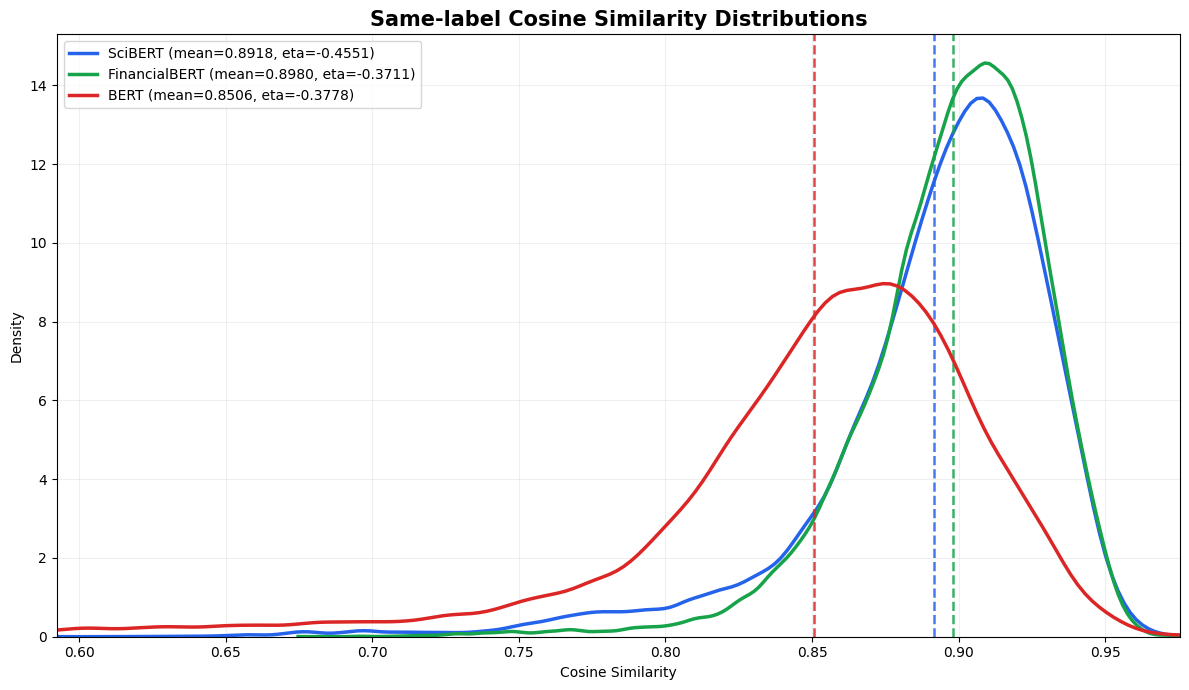

In [84]:
plt.figure(
    figsize=(12, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    scores = values["same_scores"]
    mean_value = values["same_mean"]
    eta_value = values["same_eta"]

    colour = model_colours[
        model_name
    ]

    model_label = (
        f"{short_model_names[model_name]} "
        f"(mean={mean_value:.4f}, "
        f"eta={eta_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.5,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.8,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity Distributions",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=10
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "same_label_three_models.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

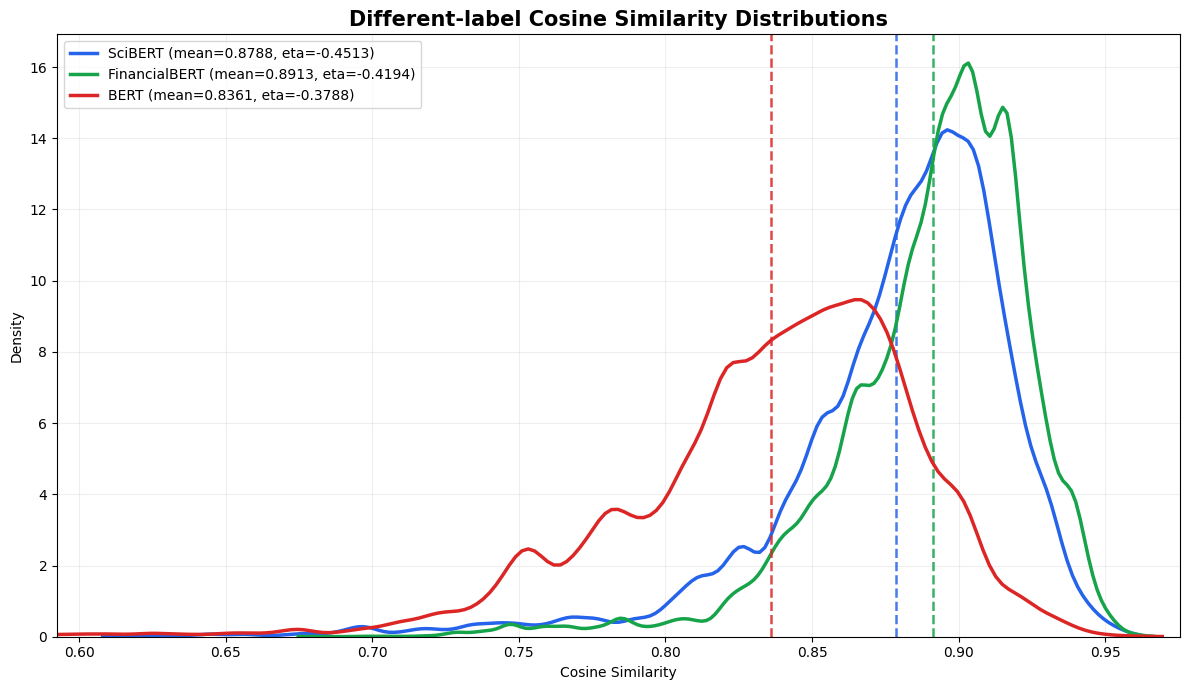

In [85]:
plt.figure(
    figsize=(12, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    scores = values["diff_scores"]
    mean_value = values["diff_mean"]
    eta_value = values["diff_eta"]

    colour = model_colours[
        model_name
    ]

    model_label = (
        f"{short_model_names[model_name]} "
        f"(mean={mean_value:.4f}, "
        f"eta={eta_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.5,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.8,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity Distributions",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=10
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "different_label_three_models.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

Text(0.5, 1.0, 'Same-label vs Different-label Distributions')

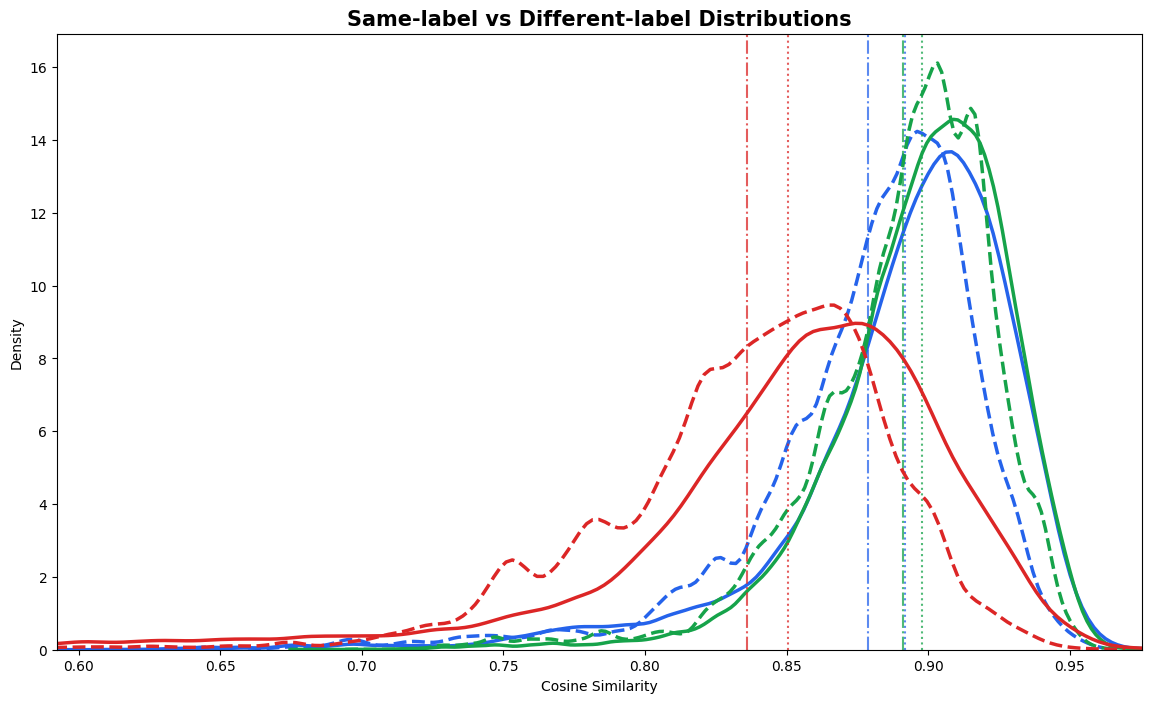

In [86]:
from matplotlib.lines import Line2D


plt.figure(
    figsize=(14, 8)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    colour = model_colours[
        model_name
    ]

    same_scores = values[
        "same_scores"
    ]

    diff_scores = values[
        "diff_scores"
    ]

    # Same-label: solid line
    sns.kdeplot(
        same_scores,
        color=colour,
        linestyle="-",
        linewidth=2.5,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
    )

    # Different-label: dashed line
    sns.kdeplot(
        diff_scores,
        color=colour,
        linestyle="--",
        linewidth=2.5,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
    )

    # Same-label mean
    plt.axvline(
        values["same_mean"],
        color=colour,
        linestyle=":",
        linewidth=1.5,
        alpha=0.75,
    )

    # Different-label mean
    plt.axvline(
        values["diff_mean"],
        color=colour,
        linestyle="-.",
        linewidth=1.5,
        alpha=0.75,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label vs Different-label Distributions",
    fontsize=15,
    fontweight="bold",
)

In [1]:
print(
    "results exists:",
    "results" in globals(),
)

if "results" in globals():
    print(
        results.keys()
    )
    print(
        list(
            results[
                "full_results"
            ].keys()
        )[:5]
    )

results exists: False
